# Bank Customer Segmentation and Credit Risk

In this project I am analysing data from a Czech bank between 1993 and 1998. It has around 4,500 accounts, more than 1 million transactions, and information about loans, cards and customers.

The goal is to group customers by how they use their accounts and to find out which customers are more likely to default on a loan.

The data is from the PKDD'99 Discovery Challenge (also called the Berka dataset), which I downloaded from Kaggle.

## Loading the data

There are 8 tables, so I load them all into one dictionary.

In [138]:
import pandas as pd
import matplotlib.pyplot as plt
import duckdb

In [139]:
table_names = ["account", "card", "client", "disp", "district", "loan", "order", "trans"]

tables = {}
for table_name in table_names:
    tables[table_name] = pd.read_csv(f"data/raw/{table_name}.csv", sep=";", low_memory=False)

`low_memory=False` makes pandas read the whole file before deciding each column's type. Without it, some pandas versions warn that the `bank` column in `trans` has mixed types.

In [140]:
for table_name, df in tables.items():
    print(f"{table_name}: {len(df):,} rows")

account: 4,500 rows
card: 892 rows
client: 5,369 rows
disp: 5,369 rows
district: 77 rows
loan: 682 rows
order: 6,471 rows
trans: 1,056,320 rows


## Exploring each table

### account

In [141]:
tables["account"].head()

,account_id,district_id,frequency,date
0,576,55,POPLATEK MESICNE,930101
1,3818,74,POPLATEK MESICNE,930101
2,704,55,POPLATEK MESICNE,930101
3,2378,16,POPLATEK MESICNE,930101
4,2632,24,POPLATEK MESICNE,930102


In [142]:
tables["account"].info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   account_id   4500 non-null   int64
 1   district_id  4500 non-null   int64
 2   frequency    4500 non-null   str  
 3   date         4500 non-null   int64
dtypes: int64(3), str(1)
memory usage: 140.8 KB


In [143]:
tables["account"]["frequency"].value_counts()

frequency
POPLATEK MESICNE      4167
POPLATEK TYDNE         240
POPLATEK PO OBRATU      93
Name: count, dtype: int64

- One row = one bank account.
- `district_id` is where the branch is, `date` is when the account was opened.
- `frequency` is how often the customer gets a statement: most accounts get one monthly (4,167), some weekly (240) and a few after every transaction (93).
- No missing values.
- `date` is stored as a number like 930101 (YYMMDD), so it needs converting.

### client

In [144]:
tables["client"].head()

,client_id,birth_number,district_id
0,1,706213,18
1,2,450204,1
2,3,406009,1
3,4,561201,5
4,5,605703,5


In [145]:
tables["client"].info()

<class 'pandas.DataFrame'>
RangeIndex: 5369 entries, 0 to 5368
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   client_id     5369 non-null   int64
 1   birth_number  5369 non-null   int64
 2   district_id   5369 non-null   int64
dtypes: int64(3)
memory usage: 126.0 KB


In [146]:
# middle two digits of birth_number should be the month
month = tables["client"]["birth_number"].astype(str).str[2:4].astype(int)
print("smallest month:", month.min())
print("largest month:", month.max())
print("clients with month above 12:", (month > 12).sum())

smallest month: 1
largest month: 62
clients with month above 12: 2645


- One row = one customer.
- `birth_number` looks like a date (YYMMDD), but 2,645 clients have a "month" between 51 and 62, which is impossible.
- From the dataset description: for women, 50 is added to the month. So this column also tells us the gender. I will decode it in the next step.

### disp

In [147]:
tables["disp"].head()

,disp_id,client_id,account_id,type
0,1,1,1,OWNER
1,2,2,2,OWNER
2,3,3,2,DISPONENT
3,4,4,3,OWNER
4,5,5,3,DISPONENT


In [148]:
tables["disp"]["type"].value_counts()

type
OWNER        4500
DISPONENT     869
Name: count, dtype: int64

- One row = one link between a customer and an account. This is how customers and accounts are connected.
- Every account has one `OWNER` (4,500). 869 accounts also have a `DISPONENT`, a second person who is allowed to use the account.
- So an account can be used by 1 or 2 people.

### card

In [149]:
tables["card"].head()

,card_id,disp_id,type,issued
0,1005,9285,classic,931107 00:00:00
1,104,588,classic,940119 00:00:00
2,747,4915,classic,940205 00:00:00
3,70,439,classic,940208 00:00:00
4,577,3687,classic,940215 00:00:00


In [150]:
tables["card"]["type"].value_counts()

type
classic    659
junior     145
gold        88
Name: count, dtype: int64

- One row = one credit card. It is linked to `disp`, not directly to the account.
- Types: classic (659), junior (145), gold (88). Only 892 of 4,500 accounts have a card.
- `issued` is stored differently from the other dates: it is text with a time added, like `931107 00:00:00`. The time is always 00:00:00, so only the first 6 characters matter.

### loan

In [151]:
tables["loan"].head()

,loan_id,account_id,date,amount,duration,payments,status
0,5314,1787,930705,96396,12,8033.0,B
1,5316,1801,930711,165960,36,4610.0,A
2,6863,9188,930728,127080,60,2118.0,A
3,5325,1843,930803,105804,36,2939.0,A
4,7240,11013,930906,274740,60,4579.0,A


In [152]:
tables["loan"]["status"].value_counts()

status
C    403
A    203
D     45
B     31
Name: count, dtype: int64

- One row = one loan. Each account has at most one loan.
- Status: A = finished and paid (203), B = finished but not paid (31), C = running and paid on time (403), D = running but the client is in debt (45).
- B and D are the bad loans: 76 out of 682, about 11%. This will be the target for the credit risk part.

### order

In [153]:
tables["order"].head()

,order_id,account_id,bank_to,account_to,amount,k_symbol
0,29401,1,YZ,87144583,2452.0,SIPO
1,29402,2,ST,89597016,3372.7,UVER
2,29403,2,QR,13943797,7266.0,SIPO
3,29404,3,WX,83084338,1135.0,SIPO
4,29405,3,CD,24485939,327.0,


In [154]:
tables["order"]["k_symbol"].value_counts()

k_symbol
SIPO        3502
            1379
UVER         717
POJISTNE     532
LEASING      341
Name: count, dtype: int64

- One row = one standing order (an automatic regular payment).
- Most are for household bills (`SIPO`, 3,502), then loan repayments (`UVER`), insurance (`POJISTNE`) and leasing.
- 1,379 orders have a blank `k_symbol` (just a space, not a real missing value), so their purpose is unknown.

### district

In [155]:
tables["district"].head()

,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12,A13,A14,A15,A16
0,1,Hl.m. Praha,Prague,1204953,0,0,0,1,1,100.0,12541,0.29,0.43,167,85677,99107
1,2,Benesov,central Bohemia,88884,80,26,6,2,5,46.7,8507,1.67,1.85,132,2159,2674
2,3,Beroun,central Bohemia,75232,55,26,4,1,5,41.7,8980,1.95,2.21,111,2824,2813
3,4,Kladno,central Bohemia,149893,63,29,6,2,6,67.4,9753,4.64,5.05,109,5244,5892
4,5,Kolin,central Bohemia,95616,65,30,4,1,6,51.4,9307,3.85,4.43,118,2616,3040


In [156]:
tables["district"].info()

<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 16 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   A1      77 non-null     int64  
 1   A2      77 non-null     str    
 2   A3      77 non-null     str    
 3   A4      77 non-null     int64  
 4   A5      77 non-null     int64  
 5   A6      77 non-null     int64  
 6   A7      77 non-null     int64  
 7   A8      77 non-null     int64  
 8   A9      77 non-null     int64  
 9   A10     77 non-null     float64
 10  A11     77 non-null     int64  
 11  A12     77 non-null     str    
 12  A13     77 non-null     float64
 13  A14     77 non-null     int64  
 14  A15     77 non-null     str    
 15  A16     77 non-null     int64  
dtypes: float64(2), int64(10), str(4)
memory usage: 9.8 KB


In [157]:
# A12 and A15 should be numbers but are stored as text. Find the value that is not a number
for col in ["A12", "A15"]:
    not_a_number = pd.to_numeric(tables["district"][col], errors="coerce").isna()
    print(col, tables["district"].loc[not_a_number, ["A2", col]].values.tolist())

A12 [['Jesenik', '?']]
A15 [['Jesenik', '?']]


- One row = one district, with demographic information. The columns are named A1 to A16; from the dataset description:
  A1 = district id, A2 = name, A3 = region, A4 = inhabitants, A5–A8 = number of towns of different sizes, A9 = number of cities, A10 = % urban inhabitants, A11 = average salary, A12/A13 = unemployment rate 1995/1996, A14 = entrepreneurs per 1,000 people, A15/A16 = number of crimes 1995/1996.
- A12 and A15 are stored as text instead of numbers because one district (Jesenik) has `?` instead of a value. The `?` needs to become a missing value.

### trans

In [158]:
tables["trans"].head()

,trans_id,account_id,date,type,operation,amount,balance,k_symbol,bank,account
0,695247,2378,930101,PRIJEM,VKLAD,700.0,700.0,NaN,NaN,NaN
1,171812,576,930101,PRIJEM,VKLAD,900.0,900.0,NaN,NaN,NaN
2,207264,704,930101,PRIJEM,VKLAD,1000.0,1000.0,NaN,NaN,NaN
3,1117247,3818,930101,PRIJEM,VKLAD,600.0,600.0,NaN,NaN,NaN
4,579373,1972,930102,PRIJEM,VKLAD,400.0,400.0,NaN,NaN,NaN


In [159]:
tables["trans"].isna().sum()

trans_id           0
account_id         0
date               0
type               0
operation     183114
amount             0
balance            0
k_symbol      481881
bank          782812
account       760931
dtype: int64

In [160]:
tables["trans"]["type"].value_counts()

type
VYDAJ     634571
PRIJEM    405083
VYBER      16666
Name: count, dtype: int64

In [161]:
tables["trans"]["operation"].value_counts(dropna=False)

operation
VYBER             434918
PREVOD NA UCET    208283
NaN               183114
VKLAD             156743
PREVOD Z UCTU      65226
VYBER KARTOU        8036
Name: count, dtype: int64

In [162]:
tables["trans"]["k_symbol"].value_counts(dropna=False)

k_symbol
NaN            481881
UROK           183114
SLUZBY         155832
SIPO           118065
                53433
DUCHOD          30338
POJISTNE        18500
UVER            13580
SANKC. UROK      1577
Name: count, dtype: int64

In [163]:
# which transactions have no operation?
tables["trans"].loc[tables["trans"]["operation"].isna(), "k_symbol"].value_counts()

k_symbol
UROK    183114
Name: count, dtype: int64

- One row = one transaction. 1,056,320 transactions.
- `type`: `PRIJEM` = money in (405,083), `VYDAJ` = money out (634,571). `VYBER` (16,666) also means money out (cash withdrawal), so both VYDAJ and VYBER are withdrawals.
- Missing values:
  - `operation` is missing for 183,114 rows. All of them are interest payments (`k_symbol` = `UROK`), which the bank adds itself, so this makes sense.
  - `k_symbol` is missing for 481,881 rows and blank for another 53,433. Most transactions simply don't have a specific purpose.
  - `bank` and `account` (the other bank and account in a transfer) are only filled for transfers to or from another bank, so they are missing for everything else. This is expected.
- Some transactions are made by the bank, not the customer: interest (`UROK`), statement fees (`SLUZBY`) and penalty interest (`SANKC. UROK`). I will keep this in mind when looking at customer behaviour.

## Summary of what needs cleaning

1. Dates in all tables are numbers like 930101 and need converting. `card.issued` also has a time part.
2. `client.birth_number` contains both the birth date and the gender.
3. Czech codes in `account`, `trans`, `order` and `loan` need translating.
4. `?` in district columns A12 and A15 should be missing values.
5. Blank `k_symbol` values (a single space) should be treated the same as missing.

## Cleaning step 1: fixing the dates

The dates are stored as numbers in YYMMDD format, for example `930101` = 1 January 1993. I convert them to real dates with `pd.to_datetime` and a format string:
- `%y` = 2-digit year
- `%m` = month
- `%d` = day

The numbers have to be turned into text first (`astype(str)`), because `pd.to_datetime` reads the format from text.

In [164]:
tables["account"]["date"] = pd.to_datetime(tables["account"]["date"].astype(str), format="%y%m%d")
tables["loan"]["date"] = pd.to_datetime(tables["loan"]["date"].astype(str), format="%y%m%d")
tables["trans"]["date"] = pd.to_datetime(tables["trans"]["date"].astype(str), format="%y%m%d")

`card.issued` is different: it is text like `931107 00:00:00`. The time is always midnight, so I only keep the first 6 characters (the date) and convert those.

In [165]:
# check the time part really is always 00:00:00 before throwing it away
print(tables["card"]["issued"].str[7:].value_counts())

tables["card"]["issued"] = pd.to_datetime(tables["card"]["issued"].str[:6], format="%y%m%d")

issued
00:00:00    892
Name: count, dtype: int64


### Checking the result

In [166]:
date_columns = {
    "account": "date",
    "loan": "date",
    "trans": "date",
    "card": "issued",
}

for table_name, col in date_columns.items():
    dates = tables[table_name][col]
    print(f"{table_name:8} {col:7} type: {dates.dtype}   from {dates.min().date()} to {dates.max().date()}")

account  date    type: datetime64[us]   from 1993-01-01 to 1997-12-29
loan     date    type: datetime64[us]   from 1993-07-05 to 1998-12-08
trans    date    type: datetime64[us]   from 1993-01-01 to 1998-12-31
card     issued  type: datetime64[us]   from 1993-11-07 to 1998-12-29


- All four columns are now real dates (`datetime64`).
- Transactions run from 1993-01-01 to 1998-12-31, so the data covers exactly 6 years.
- The ranges make sense: accounts were opened 1993–1997, loans and cards start later, and nothing is after the end of 1998.

**Note for the next step:** `%y` treats years 00–68 as 2000–2068. That is fine here because all these dates are 1993–1998, but it would be wrong for birth dates. Someone born in 1911 would become 2011. So `birth_number` needs a different approach.

## Cleaning step 2: gender and birth date from `birth_number`

`birth_number` has the form YYMMDD, with one twist: **for women, 50 is added to the month**. For example:
- `706213` → year 70, month 62, day 13 → a woman born on 13 December 1970 (62 − 50 = 12)
- `450204` → year 45, month 02, day 04 → a man born on 4 February 1945

I can't use `pd.to_datetime` with `%y` here, for two reasons: months above 12 would cause an error, and `%y` would turn a year like `11` into 2011 instead of 1911. So I split the number into its parts myself.

In [167]:
client = tables["client"]

# zfill(6) adds a leading zero if a number has fewer than 6 digits (all have 6 here, but it is a safe habit)
bn = client["birth_number"].astype(str).str.zfill(6)

year = 1900 + bn.str[0:2].astype(int)      # everyone in this data was born in the 1900s
month = bn.str[2:4].astype(int)
day = bn.str[4:6].astype(int)

client["gender"] = "M"
client.loc[month > 50, "gender"] = "F"

month = month.where(month <= 50, month - 50)   # take 50 off the women's months

client["birth_date"] = pd.to_datetime({"year": year, "month": month, "day": day})
client.head()

,client_id,birth_number,district_id,gender,birth_date
0,1,706213,18,F,1970-12-13
1,2,450204,1,M,1945-02-04
2,3,406009,1,F,1940-10-09
3,4,561201,5,M,1956-12-01
4,5,605703,5,F,1960-07-03


### Checking the result

In [168]:
print("months now range from", client["birth_date"].dt.month.min(), "to", client["birth_date"].dt.month.max())
print("birth dates range from", client["birth_date"].min().date(), "to", client["birth_date"].max().date())
print()
print(client["gender"].value_counts())

months now range from 1 to 12
birth dates range from 1911-08-20 to 1987-09-27

gender
M    2724
F    2645
Name: count, dtype: int64


- All months are now between 1 and 12, and every birth date was valid (`pd.to_datetime` would have raised an error otherwise).
- Clients were born between 1911 and 1987. Using `%y` would have wrongly put the 1911 births in 2011.
- Men and women are almost equally represented.

### Age

The data ends on 31 December 1998, so I calculate everyone's age on 1 January 1999. Using today's date would make everyone about 28 years older than they were in the data.

In [169]:
end_of_data = pd.Timestamp("1999-01-01")
client["age"] = ((end_of_data - client["birth_date"]).dt.days / 365.25).astype(int)

client["age"].describe()

count    5369.000000
mean       44.803502
std        17.282261
min        11.000000
25%        30.000000
50%        44.000000
75%        58.000000
max        87.000000
Name: age, dtype: float64

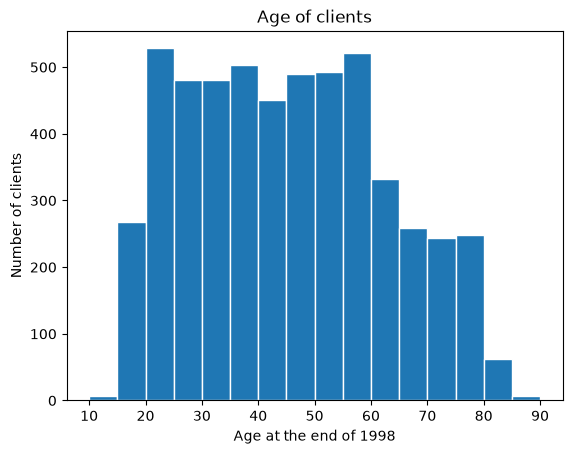

In [170]:
plt.hist(client["age"], bins=range(10, 95, 5), edgecolor="white")
plt.xlabel("Age at the end of 1998")
plt.ylabel("Number of clients")
plt.title("Age of clients")
plt.show()

- Ages range from 11 to 87. The youngest clients are children, which fits the junior cards seen earlier.
- Most clients are between about 20 and 60, with fewer older people.
- Dividing the number of days by 365.25 (the average year length, including leap years) gives the age in years; `astype(int)` rounds down, as ages normally are.

## Cleaning step 3: translating the Czech codes

Several columns use Czech words. I translate them with dictionaries and `.map()`, which replaces each value with the matching value from the dictionary. Any value that is **not** in the dictionary becomes missing (NaN), so after each translation I can check for NaN to make sure I didn't miss a code.

The meanings come from the dataset's documentation.

### account: statement frequency

In [171]:
frequency_names = {
    "POPLATEK MESICNE": "monthly",
    "POPLATEK TYDNE": "weekly",
    "POPLATEK PO OBRATU": "after each transaction",
}
tables["account"]["frequency"] = tables["account"]["frequency"].map(frequency_names)
tables["account"]["frequency"].value_counts(dropna=False)

frequency
monthly                   4167
weekly                     240
after each transaction      93
Name: count, dtype: int64

### disp: owner or authorised user

In [172]:
tables["disp"]["type"] = tables["disp"]["type"].map({"OWNER": "owner", "DISPONENT": "authorised user"})
tables["disp"]["type"].value_counts(dropna=False)

type
owner              4500
authorised user     869
Name: count, dtype: int64

### loan: status

Besides translating the status, I add an `is_bad` column: `True` for loans that were not repaid (B) or are in debt (D). This will be the target in the credit risk part.

In [173]:
status_names = {
    "A": "finished, paid",
    "B": "finished, not paid",
    "C": "running, on time",
    "D": "running, in debt",
}
tables["loan"]["status_label"] = tables["loan"]["status"].map(status_names)
tables["loan"]["is_bad"] = tables["loan"]["status"].isin(["B", "D"])

tables["loan"][["status", "status_label", "is_bad"]].value_counts().sort_index()

status  status_label        is_bad
A       finished, paid      False     203
B       finished, not paid  True       31
C       running, on time    False     403
D       running, in debt    True       45
Name: count, dtype: int64

### trans: type, operation and k_symbol

Three things to handle:
- `type` really means the **direction** of the money, so I rename it. `VYDAJ` and `VYBER` both mean money out.
- `operation` is missing only for interest payments (found earlier), so I fill those in as `"interest"`.
- `k_symbol` is sometimes a blank space instead of missing. I strip spaces first, so blanks become empty text, and then treat empty and missing the same way: `"none"`.

In [174]:
trans = tables["trans"]

trans["type"] = trans["type"].map({"PRIJEM": "credit", "VYDAJ": "debit", "VYBER": "debit"})
trans = trans.rename(columns={"type": "direction"})

operation_names = {
    "VKLAD": "cash deposit",
    "PREVOD Z UCTU": "transfer in",
    "VYBER": "cash withdrawal",
    "VYBER KARTOU": "card withdrawal",
    "PREVOD NA UCET": "transfer out",
}
trans["operation"] = trans["operation"].map(operation_names).fillna("interest")

purpose_names = {
    "POJISTNE": "insurance",
    "SLUZBY": "statement fee",
    "UROK": "interest credited",
    "SANKC. UROK": "penalty interest",
    "SIPO": "household bills",
    "DUCHOD": "pension",
    "UVER": "loan repayment",
    "LEASING": "leasing",
}
trans["k_symbol"] = trans["k_symbol"].str.strip().map(purpose_names).fillna("none")
trans = trans.rename(columns={"k_symbol": "purpose"})

tables["trans"] = trans
trans.head()

,trans_id,account_id,date,direction,operation,amount,balance,purpose,bank,account
0,695247,2378,1993-01-01,credit,cash deposit,700.0,700.0,none,NaN,NaN
1,171812,576,1993-01-01,credit,cash deposit,900.0,900.0,none,NaN,NaN
2,207264,704,1993-01-01,credit,cash deposit,1000.0,1000.0,none,NaN,NaN
3,1117247,3818,1993-01-01,credit,cash deposit,600.0,600.0,none,NaN,NaN
4,579373,1972,1993-01-02,credit,cash deposit,400.0,400.0,none,NaN,NaN


**Careful with `.fillna()`:** it fills *every* NaN, including codes I forgot to put in the dictionary. So before trusting it, I check that the only values that were missing are the ones I expected: interest for `operation`, and empty or missing for `k_symbol`.

In [175]:
raw_trans = pd.read_csv("data/raw/trans.csv", sep=";", usecols=["operation", "k_symbol"], low_memory=False)

unknown_operations = set(raw_trans["operation"].dropna()) - set(operation_names)
unknown_purposes = set(raw_trans["k_symbol"].str.strip().dropna()) - set(purpose_names) - {""}

print("operation codes not in my dictionary:", unknown_operations)
print("k_symbol codes not in my dictionary: ", unknown_purposes)

operation codes not in my dictionary: set()
k_symbol codes not in my dictionary:  set()


In [176]:
print(trans["direction"].value_counts(), "\n")
print(trans["operation"].value_counts(), "\n")
print(trans["purpose"].value_counts())

direction
debit     651237
credit    405083
Name: count, dtype: int64 

operation
cash withdrawal    434918
transfer out       208283
interest           183114
cash deposit       156743
transfer in         65226
card withdrawal      8036
Name: count, dtype: int64 

purpose
none                 535314
interest credited    183114
statement fee        155832
household bills      118065
pension               30338
insurance             18500
loan repayment        13580
penalty interest       1577
Name: count, dtype: int64


Every Czech code had a translation, so nothing was filled in by mistake. The counts match what I found while exploring, for example 183,114 interest rows and 16,666 + 634,571 = 651,237 debits.

### order: purpose

Same idea as `k_symbol` in transactions. Here a blank means the purpose of the standing order is unknown.

In [177]:
order = tables["order"]
order["k_symbol"] = order["k_symbol"].str.strip().map(purpose_names).fillna("unknown")
tables["order"] = order.rename(columns={"k_symbol": "purpose"})

tables["order"]["purpose"].value_counts()

purpose
household bills    3502
unknown            1379
loan repayment      717
insurance           532
leasing             341
Name: count, dtype: int64

### district: readable column names and the `?` values

Not a translation, but the same kind of clean-up: I give the `A1`–`A16` columns readable names, and turn the `?` in Jesenik into a real missing value with `pd.to_numeric(..., errors="coerce")`, which turns anything that isn't a number into NaN.

In [178]:
district_columns = {
    "A1": "district_id",
    "A2": "district_name",
    "A3": "region",
    "A4": "inhabitants",
    "A5": "towns_under_500",
    "A6": "towns_500_1999",
    "A7": "towns_2000_9999",
    "A8": "towns_over_10000",
    "A9": "n_cities",
    "A10": "urban_ratio",
    "A11": "avg_salary",
    "A12": "unemployment_1995",
    "A13": "unemployment_1996",
    "A14": "entrepreneurs_per_1000",
    "A15": "crimes_1995",
    "A16": "crimes_1996",
}
district = tables["district"].rename(columns=district_columns)
district["unemployment_1995"] = pd.to_numeric(district["unemployment_1995"], errors="coerce")
district["crimes_1995"] = pd.to_numeric(district["crimes_1995"], errors="coerce")
tables["district"] = district

district[["district_name", "unemployment_1995", "crimes_1995"]].isna().sum()

district_name        0
unemployment_1995    1
crimes_1995          1
dtype: int64

Only one value is missing in each of the two columns (Jesenik), and both columns are numbers now. The 1996 versions of these columns are complete, so I will use those later.

All five clean-up jobs from the exploration are now done:
1. Dates converted ✓
2. Gender and birth date from `birth_number` ✓
3. Czech codes translated ✓
4. `?` in district replaced ✓
5. Blank `k_symbol` treated as missing ✓

## Data-quality checks

Before analysing anything, I check that the tables fit together the way the documentation says. If they don't, every result built on top of them could be wrong.

### Do the tables link up correctly?

In [179]:
account = tables["account"]
disp = tables["disp"]
card = tables["card"]
loan = tables["loan"]
trans = tables["trans"]

owners_per_account = disp[disp["type"] == "owner"].groupby("account_id").size()
loan_dates = loan.merge(account[["account_id", "date"]], on="account_id", suffixes=("_loan", "_opened"))
trans_dates = trans[["account_id", "date"]].merge(
    account[["account_id", "date"]], on="account_id", suffixes=("_trans", "_opened"))

checks = {
    "every account has exactly one owner":
        (owners_per_account == 1).all() and len(owners_per_account) == len(account),
    "every account appears in disp":
        account["account_id"].isin(disp["account_id"]).all(),
    "every transaction belongs to a known account":
        trans["account_id"].isin(account["account_id"]).all(),
    "every card belongs to a known disp":
        card["disp_id"].isin(disp["disp_id"]).all(),
    "at most one loan per account":
        loan["account_id"].is_unique,
    "no loan before its account was opened":
        (loan_dates["date_loan"] >= loan_dates["date_opened"]).all(),
    "no transaction before its account was opened":
        (trans_dates["date_trans"] >= trans_dates["date_opened"]).all(),
}

for name, passed in checks.items():
    print("PASS" if passed else "FAIL", " ", name)

PASS   every account has exactly one owner
PASS   every account appears in disp
PASS   every transaction belongs to a known account
PASS   every card belongs to a known disp
PASS   at most one loan per account
PASS   no loan before its account was opened
PASS   no transaction before its account was opened


All checks pass, so the tables are linked correctly and the events happen in a sensible order.

### Do the balances add up?

Each transaction stores the account `balance` **after** that transaction. So, in theory:

> balance now = previous balance + money in − money out

To check this, I first add a **signed amount**: positive for credits and negative for debits. Then I sort each account's transactions by date and compare every balance with the one before it. Transactions have no time of day, so for transactions on the same day I use `trans_id` as the order.

In [180]:
trans["signed_amount"] = trans["amount"].where(trans["direction"] == "credit", -trans["amount"])

trans = trans.sort_values(["account_id", "date", "trans_id"]).reset_index(drop=True)
trans["prev_balance"] = trans.groupby("account_id")["balance"].shift(1)

checked = trans.dropna(subset=["prev_balance"])
matches = (checked["prev_balance"] + checked["signed_amount"] - checked["balance"]).abs() < 0.01

print(f"transactions checked: {len(checked):,}")
print(f"balance adds up:      {matches.sum():,} ({matches.mean():.1%})")

transactions checked: 1,051,820
balance adds up:      520,736 (49.5%)


Only about half of the balances add up. That is a lot of mismatches. Either the data is badly broken, or my check makes a wrong assumption. Let me look at one example.

In [181]:
# first mismatch for account 1, with the transaction just before it
mismatch_rows = checked.loc[~matches]
first_index = mismatch_rows[mismatch_rows["account_id"] == 1].index[0]

example = trans.loc[first_index - 1 : first_index + 1,
                    ["trans_id", "date", "operation", "purpose", "signed_amount", "balance"]]
example

,trans_id,date,operation,purpose,signed_amount,balance
14,203,1995-08-21,cash withdrawal,none,-7500.0,21402.7
15,159,1995-08-31,cash withdrawal,statement fee,-14.6,21487.3
16,3530442,1995-08-31,interest,interest credited,99.2,21501.9


In [182]:
start, fee, interest = example["balance"].iloc[0], example["signed_amount"].iloc[1], example["signed_amount"].iloc[2]

print(f"stored order (fee first):     {start} + ({fee}) = {start + fee:.1f}, but the stored balance is {example['balance'].iloc[1]}")
print(f"interest first, then the fee: {start} + {interest} = {start + interest:.1f}, then {start + interest:.1f} + ({fee}) = {start + interest + fee:.1f}")

stored order (fee first):     21402.7 + (-14.6) = 21388.1, but the stored balance is 21487.3
interest first, then the fee: 21402.7 + 99.2 = 21501.9, then 21501.9 + (-14.6) = 21487.3


The two transactions on the last day of the month are the bank's interest payment and the statement fee. Sorted by `trans_id`, the fee comes first. But the balances only work out if the **interest came first**: previous balance + interest = the interest row's balance, and then minus the fee = the fee row's balance.

So the problem is the **order within a day**. `trans_id` does not reflect the order the bank processed the transactions in, and the data has no time of day to sort by. This also explains why mismatches are so common: once one day is in the wrong order, the first transaction of the next day is compared with the wrong "previous" balance and fails too.

In [183]:
mismatches = checked.loc[~matches].copy()
mismatches["prev_date"] = trans.groupby("account_id")["date"].shift(1).loc[mismatches.index]

same_day = (mismatches["date"] == mismatches["prev_date"]).sum()
print(f"mismatches:                                    {len(mismatches):,}")
print(f"  on the same day as the previous transaction: {same_day:,}")
print(f"  on a new day:                                {len(mismatches) - same_day:,}")

mismatches:                                    531,084
  on the same day as the previous transaction: 186,963
  on a new day:                                344,121


### A better check: one balance per day

Since the order *within* a day can't be trusted, I check at the **day** level instead. The account balance at the end of each day should equal the running total of all money in and out up to that day (accounts start at 0). This doesn't depend on the order within the day.

For each account and day:
1. Add up the signed amounts → `net_flow`.
2. Take the running total of `net_flow` → `running_total`.
3. One of that day's stored balances should equal `running_total`. That one is the real end-of-day balance.

In [184]:
daily = (trans.groupby(["account_id", "date"])
              .agg(net_flow=("signed_amount", "sum"), n_transactions=("trans_id", "count"))
              .reset_index())
daily["running_total"] = daily.groupby("account_id")["net_flow"].cumsum()

# compare every stored balance that day with the running total, and keep the closest one
with_total = trans[["account_id", "date", "balance"]].merge(daily, on=["account_id", "date"])
with_total["gap"] = (with_total["balance"] - with_total["running_total"]).abs()
closest = with_total.loc[with_total.groupby(["account_id", "date"])["gap"].idxmin()]

daily_balance = closest[["account_id", "date", "net_flow", "n_transactions", "balance", "gap"]]
daily_balance = daily_balance.rename(columns={"balance": "end_of_day_balance"}).reset_index(drop=True)

print(f"account-days checked:  {len(daily_balance):,}")
print(f"largest gap:           {daily_balance['gap'].max():.2f} CZK")
print(f"within 1 CZK:          {(daily_balance['gap'] < 1).mean():.2%}")

account-days checked:  814,768
largest gap:           2.80 CZK
within 1 CZK:          99.14%


Checked by day, every one of the 815,000 account-days matches to within 3 CZK, and over 99% match to within 1 CZK. The tiny gaps build up slowly over the years because the amounts are stored rounded to 0.1 CZK.

**Conclusion:**
- The amounts and balances are consistent. The data is reliable.
- The order of transactions *within* a day is not reliable, so later notebooks should not use the balance after individual transactions.
- `daily_balance` gives one trustworthy **end-of-day balance** per account and day, which is what I will use for balances from now on.

In [185]:
trans = trans.drop(columns="prev_balance")
tables["trans"] = trans
daily_balance.head()

,account_id,date,net_flow,n_transactions,end_of_day_balance,gap
0,1,1995-03-24,1000.0,1,1000.0,0.0
1,1,1995-04-13,3679.0,1,4679.0,0.0
2,1,1995-04-23,12600.0,1,17279.0,0.0
3,1,1995-04-30,19.2,1,17298.2,0.0
4,1,1995-05-13,3679.0,1,20977.2,0.0


## One row per account, using SQL

Most of the later analysis is per account, so I combine the tables into one account-level table. Joining several tables is exactly what SQL is made for, so I use **DuckDB**, a small SQL database that runs inside Python and can query pandas DataFrames directly.

First I register my cleaned DataFrames, so SQL can refer to them by name.

In [186]:
con = duckdb.connect()   # an in-memory database: nothing is saved to disk

for name in ["account", "client", "disp", "card", "loan", "district", "trans"]:
    con.register(name, tables[name])

The joins:
- `disp` connects each account to its **owner** in `client` (every account has exactly one owner, checked earlier).
- `district` adds information about where the account's branch is.
- `card` and `loan` are **LEFT JOIN**s, because most accounts have neither. A normal (inner) join would drop those accounts.
- All 892 cards belong to account owners, so joining cards through the owner's `disp_id` doesn't miss any.

In [187]:
account_profile = con.sql("""
    SELECT
        a.account_id,
        a.date              AS opened,
        a.frequency         AS statement_frequency,
        c.client_id         AS owner_id,
        c.gender            AS owner_gender,
        c.age               AS owner_age,
        dist.district_name,
        dist.region,
        dist.avg_salary         AS district_avg_salary,
        dist.unemployment_1996  AS district_unemployment,
        a.account_id IN (SELECT account_id FROM disp WHERE type = 'authorised user') AS has_second_user,
        card.type           AS card_type,
        loan.loan_id IS NOT NULL AS has_loan,
        loan.is_bad         AS loan_is_bad
    FROM account a
    JOIN disp d            ON d.account_id = a.account_id AND d.type = 'owner'
    JOIN client c          ON c.client_id = d.client_id
    JOIN district dist     ON dist.district_id = a.district_id
    LEFT JOIN card         ON card.disp_id = d.disp_id
    LEFT JOIN loan         ON loan.account_id = a.account_id
    ORDER BY a.account_id
""").df()

print(f"{len(account_profile):,} rows, one per account: {account_profile['account_id'].is_unique}")
account_profile.head()

4,500 rows, one per account: True


,account_id,opened,statement_frequency,owner_id,owner_gender,owner_age,district_name,region,district_avg_salary,district_unemployment,has_second_user,card_type,has_loan,loan_is_bad
0,1,1995-03-24,monthly,1,F,28,Pisek,south Bohemia,8968,3.35,False,NaN,False,<NA>
1,2,1993-02-26,monthly,2,M,53,Hl.m. Praha,Prague,12541,0.43,True,NaN,True,False
2,3,1997-07-07,monthly,4,M,42,Kolin,central Bohemia,9307,4.43,True,NaN,False,<NA>
3,4,1996-02-21,monthly,6,M,79,Pribram,central Bohemia,8754,4.31,False,NaN,False,<NA>
4,5,1997-05-30,monthly,7,M,69,Cesky Krumlov,south Bohemia,9045,3.60,False,NaN,False,<NA>


4,500 rows, one per account, so no account was lost or duplicated by the joins.

### A first summary of the bank, in SQL

In [188]:
con.register("account_profile", account_profile)

con.sql("""
    SELECT
        COUNT(*)                                       AS accounts,
        ROUND(AVG(owner_age), 1)                       AS avg_owner_age,
        ROUND(100 * AVG((owner_gender = 'F')::INT), 1) AS pct_female_owners,
        ROUND(100 * AVG(has_second_user::INT), 1)      AS pct_with_second_user,
        ROUND(100 * AVG((card_type IS NOT NULL)::INT), 1) AS pct_with_card,
        ROUND(100 * AVG(has_loan::INT), 1)             AS pct_with_loan,
        ROUND(100 * AVG(loan_is_bad::INT), 1)          AS pct_bad_of_loans
    FROM account_profile
""").df().T.rename(columns={0: "value"})

,value
accounts,4500.0
avg_owner_age,44.1
pct_female_owners,49.1
pct_with_second_user,19.3
pct_with_card,19.8
pct_with_loan,15.2
pct_bad_of_loans,11.1


In [189]:
# accounts and bad loans by region
con.sql("""
    SELECT
        region,
        COUNT(*)                         AS accounts,
        SUM(has_loan::INT)::INT          AS loans,
        SUM(COALESCE(loan_is_bad, FALSE)::INT)::INT AS bad_loans,
        ROUND(100.0 * SUM(COALESCE(loan_is_bad, FALSE)::INT) / NULLIF(SUM(has_loan::INT), 0), 1) AS pct_bad
    FROM account_profile
    GROUP BY region
    ORDER BY accounts DESC
""").df()

,region,accounts,loans,bad_loans,pct_bad
0,north Moravia,793,117,18,15.4
1,south Moravia,778,129,13,10.1
2,central Bohemia,574,90,10,11.1
3,Prague,554,84,7,8.3
4,east Bohemia,544,84,9,10.7
5,north Bohemia,457,61,1,1.6
6,west Bohemia,430,57,9,15.8
7,south Bohemia,370,60,9,15.0


- `AVG(loan_is_bad)` only averages accounts that have a loan, because `loan_is_bad` is empty (NULL) for the others, and SQL's `AVG` skips NULLs. So 11.1% is the share of **loans** that are bad.
- The share of bad loans differs between regions, but some regions have only around 50–100 loans, so a difference of a few loans changes the percentage a lot. I will look at this properly in the credit risk part.

## Saving the clean tables

I save everything to `data/clean/` as **Parquet** files. Unlike CSV, Parquet keeps the column types (dates stay dates), is compressed, and loads much faster. The next notebooks start from these files instead of repeating all the cleaning.

(Parquet needs the `pyarrow` package: `pip install pyarrow`.)

In [190]:
from pathlib import Path

clean_dir = Path("data/clean")
clean_dir.mkdir(parents=True, exist_ok=True)

to_save = {**tables, "daily_balance": daily_balance, "account_profile": account_profile}

for name, df in to_save.items():
    df.to_parquet(clean_dir / f"{name}.parquet", index=False)
    print(f"{name:16} {len(df):>10,} rows")

account               4,500 rows
card                    892 rows
client                5,369 rows
disp                  5,369 rows
district                 77 rows
loan                    682 rows
order                 6,471 rows
trans             1,056,320 rows
daily_balance       814,768 rows
account_profile       4,500 rows


## Summary of step 1

**What I did**
- Loaded the 8 tables and explored each one.
- Converted the dates, decoded gender, birth date and age from `birth_number`, and translated the Czech codes.
- Checked that the tables link correctly: all 7 checks passed.
- Built one table per account with SQL, and saved all clean tables as Parquet.

**What I found**
- **Women's birth numbers have 50 added to the month**, which is how gender is stored.
- **The order of transactions within a day is wrong in the data.** A simple balance check failed on half the transactions; checked per day, the balances match to within 3 CZK. So I only use end-of-day balances.
- **11% of loans are bad** (76 of 682). This is the target for the credit risk part.

**Next:** step 2 looks at how activity and balances change over time.